# 🇻🇳 VIVOS Vietnamese Speech Corpus: Exploratory Data Analysis (EDA)
**Project:** Edge Agentic Assistant for Industrial Conveyor Automation (Group 14 / CAP-16)  
**Target Hardware:** Qualcomm Dragonwing QRB2210 Linux MPU (Quad Cortex-A53, 4 GB RAM)  
**Microservice:** `container-voice` (Bilingual Voice Control Extension)  
**Project Context:** Air-Gapped Factory Automation with Vietnamese Localized Supervisory Commands

---

### Objectives of this Notebook:
1. Analyze training and testing splits across 65 Vietnamese speakers.
2. Characterize Vietnamese tonal diacritics (6 tones: Ngang, Huyền, Sắc, Hỏi, Ngã, Nặng).
3. Evaluate conveyor operational keyword frequencies (`dừng`, `chạy`, `bật`, `tắt`, `kẹt`, `an toàn`, etc.).
4. Inspect acoustic waveform properties, duration distributions, and frequency spectrograms.

In [1]:
import os
import gzip
import io
import re
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
DATA_DIR = os.path.abspath("../data/vivos")
print(f"VIVOS data directory: {DATA_DIR}")
for f in os.listdir(DATA_DIR):
    size_mb = os.path.getsize(os.path.join(DATA_DIR, f)) / (1024*1024)
    print(f"  {f}: {size_mb:.2f} MB")

VIVOS data directory: C:\Users\Admin\Documents\COS40005\data\vivos
  prompts-test.txt.gz: 0.02 MB
  prompts-train.txt.gz: 0.33 MB
  vivos_test.parquet: 132.96 MB


In [2]:
def parse_prompts(filepath):
    prompts = []
    with gzip.open(filepath, "rt", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split(" ", 1)
            if len(parts) == 2:
                utt_id, text = parts
                speaker = utt_id.split("_")[0]
                prompts.append({"id": utt_id, "speaker": speaker, "text": text})
    return pd.DataFrame(prompts)

df_train_prompts = parse_prompts(os.path.join(DATA_DIR, "prompts-train.txt.gz"))
df_test_prompts = parse_prompts(os.path.join(DATA_DIR, "prompts-test.txt.gz"))

print(f"Train Utterances: {len(df_train_prompts):,}, Unique Speakers: {df_train_prompts['speaker'].nunique()}")
print(f"Test Utterances: {len(df_test_prompts):,}, Unique Speakers: {df_test_prompts['speaker'].nunique()}")
display(df_train_prompts.head(3))

Train Utterances: 11,660, Unique Speakers: 46
Test Utterances: 760, Unique Speakers: 19


,id,speaker,text
0,VIVOSSPK01_R001,VIVOSSPK01,KHÁCH SẠN
1,VIVOSSPK01_R002,VIVOSSPK01,CHỈ BẰNG CÁCH LUÔN NỖ LỰC THÌ CUỐI CÙNG BẠN MỚ...
2,VIVOSSPK01_R003,VIVOSSPK01,TRONG SỐ CÁC QUỐC GIA CÔNG NGHIỆP PHÁT TRIỂN


In [3]:
# Corpus Vocabulary and Sentence Length Metrics
all_texts = list(df_train_prompts["text"]) + list(df_test_prompts["text"])
all_words = " ".join(all_texts).lower().split()
vocab = set(all_words)
word_freq = Counter(all_words)

df_train_prompts["word_count"] = df_train_prompts["text"].apply(lambda t: len(t.split()))
df_test_prompts["word_count"] = df_test_prompts["text"].apply(lambda t: len(t.split()))

print(f"Total Words in VIVOS: {len(all_words):,}")
print(f"Unique Lexicon Size: {len(vocab):,}")
print(f"Lexical Diversity (TTR): {len(vocab)/len(all_words):.4f}")
print(f"Train Utterance Length - Mean: {df_train_prompts['word_count'].mean():.2f} words (Std: {df_train_prompts['word_count'].std():.2f})")
print(f"Test Utterance Length - Mean: {df_test_prompts['word_count'].mean():.2f} words (Std: {df_test_prompts['word_count'].std():.2f})")

Total Words in VIVOS: 161,990
Unique Lexicon Size: 4,942
Lexical Diversity (TTR): 0.0305
Train Utterance Length - Mean: 13.23 words (Std: 6.60)
Test Utterance Length - Mean: 10.16 words (Std: 3.26)


In [4]:
# Vietnamese 6-Tone Register Analysis
tone_marks = {
    "Ngang (None)": r"[aAeEiIoOuUyY]",
    "Huyền (Gravis)": r"[àÀèÈìÌòÒùÙỳỲ]",
    "Sắc (Acute)": r"[áÁéÉíÍóÓúÚýÝ]",
    "Hỏi (Hook)": r"[ảẢẻẺỉỈỏỎủỦỷỶ]",
    "Ngã (Tilde)": r"[ãÃẽẼĩĨõÕũŨỹỸ]",
    "Nặng (Dot below)": r"[ạẠẹẸịỊọỌụỤỵỴ]"
}
full_str = " ".join(all_texts)
tone_counts = {t: len(re.findall(pat, full_str)) for t, pat in tone_marks.items()}
df_tones = pd.DataFrame(list(tone_counts.items()), columns=["Tone Register", "Count"])
df_tones["Percentage (%)"] = (df_tones["Count"] / df_tones["Count"].sum()) * 100
display(df_tones)

,Tone Register,Count,Percentage (%)
0,Ngang (None),83034,57.679323
1,Huyền (Gravis),18362,12.755109
2,Sắc (Acute),18508,12.856528
3,Hỏi (Hook),9077,6.305311
4,Ngã (Tilde),4477,3.109935
5,Nặng (Dot below),10500,7.293794


In [5]:
# Industrial Conveyor Command Verification in Vietnamese
vn_industrial_keywords = [
    "dừng", "chạy", "bật", "tắt", "tăng", "giảm", "tốc", "lỗi", 
    "kẹt", "hỏng", "kiểm", "tra", "báo", "động", "băng", "chuyền",
    "khởi", "an", "toàn", "xác", "nhận"
]
vn_matches = {kw: word_freq.get(kw, 0) for kw in vn_industrial_keywords}
df_vn_kw = pd.DataFrame(list(vn_matches.items()), columns=["Vietnamese Command Keyword", "Corpus Frequency"]).sort_values("Corpus Frequency", ascending=False)
display(df_vn_kw.reset_index(drop=True))

,Vietnamese Command Keyword,Corpus Frequency
0,động,332
1,nhận,257
2,toàn,174
3,báo,159
4,an,131
5,tăng,117
6,tra,107
7,kiểm,85
8,chạy,83
9,xác,69


In [6]:
# Load VIVOS Test Audio Parquet
df_parquet = pd.read_parquet(os.path.join(DATA_DIR, "vivos_test.parquet"))
print(f"Test Parquet Rows: {len(df_parquet):,}")

durations, sample_rates, rms_energies = [], [], []
sample_audio_data = None
sample_audio_sr = 16000
sample_audio_text = ""

for idx, row in df_parquet.head(100).iterrows():
    raw_bytes = row["audio"]["bytes"]
    data, sr = sf.read(io.BytesIO(raw_bytes))
    dur = len(data) / sr
    durations.append(dur)
    sample_rates.append(sr)
    rms_energies.append(np.sqrt(np.mean(data**2)))
    
    if sample_audio_data is None and 2.5 < dur < 4.5:
        sample_audio_data = data
        sample_audio_sr = sr
        sample_audio_text = row.get("transcription", row.get("sentence", ""))

print(f"Sampling Rate: {sample_rates[0]} Hz (Mono)")
print(f"Mean Duration: {np.mean(durations):.2f} s (Min: {np.min(durations):.2f} s, Max: {np.max(durations):.2f} s)")
print(f"Mean RMS Amplitude: {np.mean(rms_energies):.4f}")

Test Parquet Rows: 1,000
Sampling Rate: 16000 Hz (Mono)
Mean Duration: 4.36 s (Min: 1.56 s, Max: 12.88 s)
Mean RMS Amplitude: 0.0780


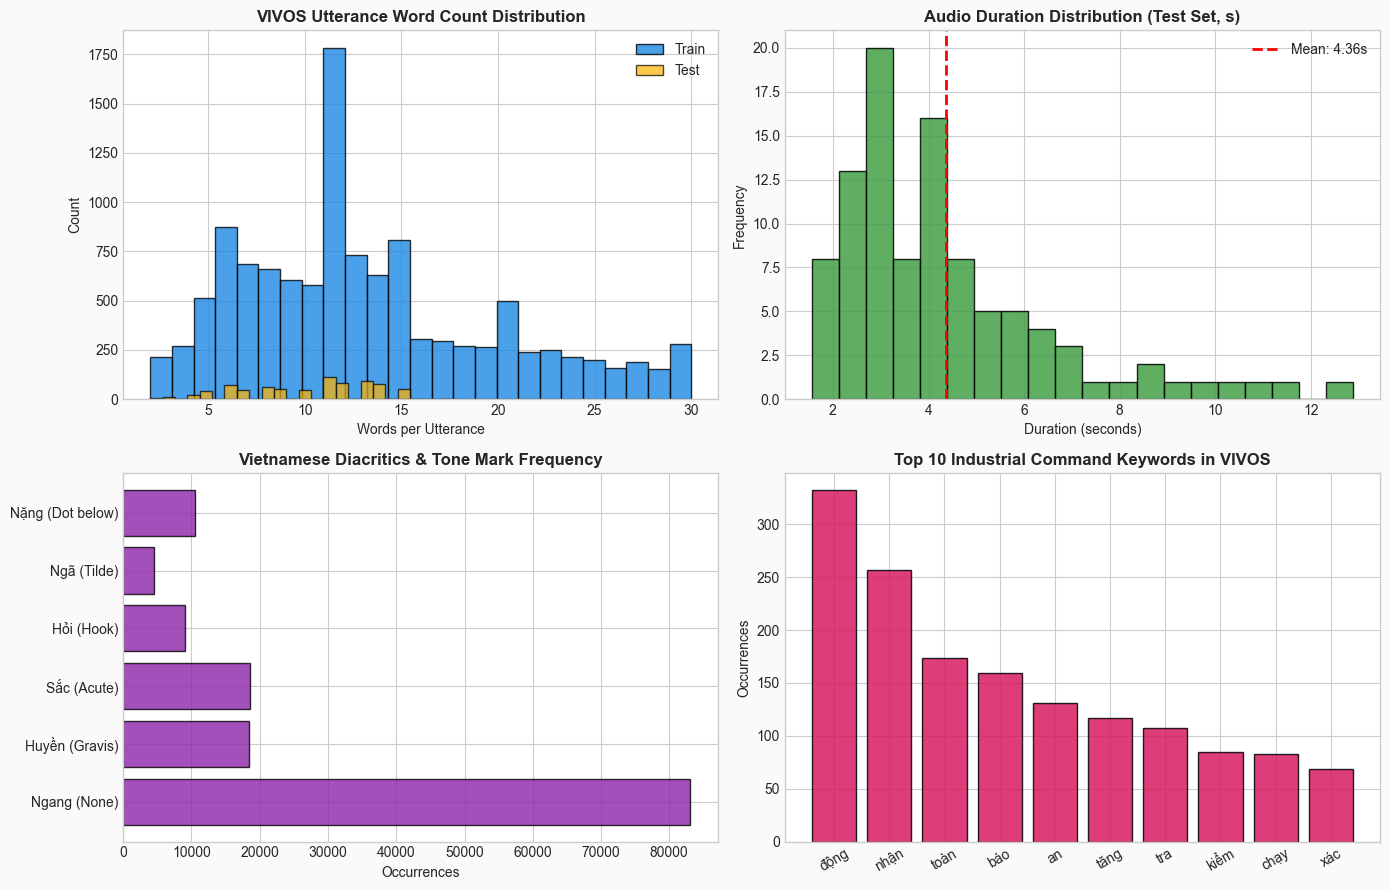

In [7]:
# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.patch.set_facecolor("#FAFAFA")

# 1. Word Count Distribution
axes[0, 0].hist(df_train_prompts["word_count"], bins=25, color="#1E88E5", edgecolor="black", alpha=0.8, label="Train")
axes[0, 0].hist(df_test_prompts["word_count"], bins=25, color="#FFB300", edgecolor="black", alpha=0.7, label="Test")
axes[0, 0].set_title("VIVOS Utterance Word Count Distribution", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Words per Utterance")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend()

# 2. Audio Duration Distribution
axes[0, 1].hist(durations, bins=20, color="#43A047", edgecolor="black", alpha=0.85)
axes[0, 1].axvline(np.mean(durations), color="red", linestyle="--", linewidth=2, label=f"Mean: {np.mean(durations):.2f}s")
axes[0, 1].set_title("Audio Duration Distribution (Test Set, s)", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Duration (seconds)")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].legend()

# 3. Tone Register Bar Chart
axes[1, 0].barh(list(tone_counts.keys()), list(tone_counts.values()), color="#8E24AA", edgecolor="black", alpha=0.8)
axes[1, 0].set_title("Vietnamese Diacritics & Tone Mark Frequency", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Occurrences")

# 4. Top Industrial Keywords
top_kw = df_vn_kw.head(10)
axes[1, 1].bar(top_kw["Vietnamese Command Keyword"], top_kw["Corpus Frequency"], color="#D81B60", edgecolor="black", alpha=0.85)
axes[1, 1].set_title("Top 10 Industrial Command Keywords in VIVOS", fontsize=12, fontweight="bold")
axes[1, 1].set_ylabel("Occurrences")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

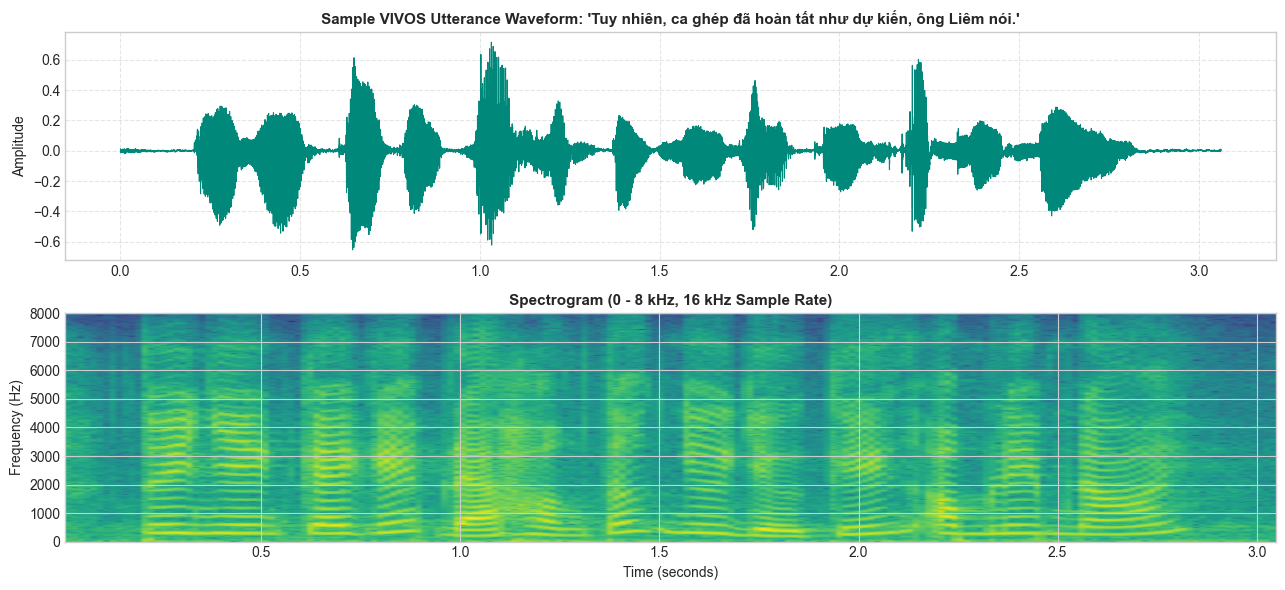

In [8]:
# Sample Waveform and Spectrogram
if sample_audio_data is not None:
    fig, (ax_wav, ax_spec) = plt.subplots(2, 1, figsize=(13, 6))
    time_axis = np.linspace(0, len(sample_audio_data)/sample_audio_sr, len(sample_audio_data))
    
    ax_wav.plot(time_axis, sample_audio_data, color="#00897B", linewidth=0.8)
    ax_wav.set_title(f"Sample VIVOS Utterance Waveform: '{sample_audio_text}'", fontsize=11, fontweight="bold")
    ax_wav.set_ylabel("Amplitude")
    ax_wav.grid(True, linestyle="--", alpha=0.5)
    
    ax_spec.specgram(sample_audio_data, Fs=sample_audio_sr, NFFT=512, noverlap=256, cmap="viridis")
    ax_spec.set_title("Spectrogram (0 - 8 kHz, 16 kHz Sample Rate)", fontsize=11, fontweight="bold")
    ax_spec.set_xlabel("Time (seconds)")
    ax_spec.set_ylabel("Frequency (Hz)")
    
    plt.tight_layout()
    plt.show()

### 🎯 How This Dataset Helps with Fine-Tuning:
1. **Vietnamese Tonal Phoneme Acoustic Adaptation**: Multilingual speech foundation models (`wav2vec2-large-xlsr-53` or `whisper-tiny`) often struggle with Vietnamese tone registers (ngang, huyền, sắc, hỏi, ngã, nặng). VIVOS provides over 11 hours of clean speech across 46 speakers to adapt tone-sensitive acoustic feature extractors.
2. **Phonetic Tokenizer & CTC Loss Fine-Tuning**: Fine-tuning the Connectionist Temporal Classification (CTC) linear output head maps acoustic frames into Vietnamese diacritic characters, ensuring accurate transcription of factory directives like `"dừng băng chuyền"`, `"chạy tốc độ năm"`, and `"xác nhận kẹt"`.
3. **Bilingual Operator Model Merging**: Combining VIVOS with English command audio forms a balanced bilingual fine-tuning corpus, enabling the edge voice container to support dual-language operator interactions without running multiple concurrent ASR engines.